<a href="https://colab.research.google.com/github/manfredialdo/iad-tpi01/blob/main/Manfredi_Aldo_Comision10_Entrega4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Integrador - Entrega 4
## Análisis Exploratorio de Datos (EDA)
---

* **Apellido y Nombre:** Manfredi Aldo Dario
* **Comisión:** 10
* **Entrega:** 4
* **Dataset asignado:**  hotel booking TPI grupo J.csv
* **Variable objetivo:** `is_canceled`
* **Recorrido elegido:** SQL + Python
* **Fecha:** Domingo 11 de octubre de 2026, 23:59 hs.
* **Repositorio:** https://github.com/manfredialdo/iad-tpi01
* **Archivo:** Manfredi_Aldo_Comision10_Entrega4.ipynb

---
---

## 1. Introducción y Preparación

En esta cuarta etapa del TPI se profundiza el análisis exploratorio de las reservas hoteleras para comparar grupos, reconocer patrones e interpretar los resultados con prudencia, sin asumir relaciones causales ni construir todavía modelos predictivos.

---
---

## 2. Selección de Preguntas o Hipótesis Exploratorias


3. **Pregunta 3:** ¿El tipo de depósito (`deposit_type`) permite reconocer grupos con comportamientos de cancelación diferentes?



1. **country (País de origen):** ¿Existe una correlación directa entre el país de origen del huésped (turismo local vs. internacional) y la tasa de cancelación, y este comportamiento varía según sea un City Hotel o un Resort?

2. **company (Identificador de empresa):** ¿Qué convenios o cuentas corporativas específicas concentran las cancelaciones masivas de reservas dentro de los City Hotels?

3. **market_segment (Segmento de mercado):** ¿Qué canales de distribución comercial generan mayor volatilidad de cancelaciones ("clientes golondrina") al comparar los hoteles urbanos con los vacacionales?


3. **Pregunta 3:** ¿El tipo de depósito (`deposit_type`) permite reconocer grupos con comportamientos de cancelación diferentes?

---


TPI

1. Selección de tres preguntas o hipótesis: elegí tres de las propuestas durante la Semana 9. Podés reformularlas si la exploración inicial mostró que necesitan mayor precisión.
2. Comparación mediante SQL: para cada pregunta, construí una o más consultas que permitan filtrar, agrupar y comparar reservas canceladas y no canceladas o los grupos que resulten pertinentes.
3. Resúmenes descriptivos: incorporá cantidades de casos, proporciones, promedios u otras medidas adecuadas. Cuando corresponda, considerá también la variabilidad y el tamaño de los grupos.
4. Visualizaciones exploratorias: construí con Python o R gráficos que permitan observar y comunicar las comparaciones realizadas.
5. Interpretación: explicá qué muestran las consultas y los gráficos, diferenciando el resultado obtenido de su interpretación.
6. Patrones y casos llamativos: identificá diferencias, relaciones, anomalías o segmentos que merezcan atención, sin eliminar ni corregir automáticamente los casos inusuales.
7. Variables candidatas: seleccioná y justificá las variables que podrían aportar información para predecir cancelaciones en las etapas posteriores.
8. Conclusiones exploratorias: sintetizá tres hallazgos respaldados por la evidencia obtenida.
9. Alcances y limitaciones: indicá al menos dos aspectos que todavía no pueden afirmarse o que requerirían análisis adicional.


<h2>carga</h2>

In [ ]:
# ==========================================
# PREPARACIÓN DEL ENTORNO Y CARGA
# ==========================================
import importlib.util
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

if importlib.util.find_spec("duckdb") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "duckdb"])

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Carga del dataset desde el repositorio
# Carga del dataset desde el repositorio y limpieza de espacios en los nombres de columnas
DATA_URL = "https://raw.githubusercontent.com/manfredialdo/iad-tpi01/refs/heads/main/hotel%20booking%20TPI%20grupo%20J.csv"
df_hotel = pd.read_csv(DATA_URL)

# Limpia los espacios en blanco que puedan venir en los nombres de las columnas del CSV
df_hotel.columns = df_hotel.columns.str.strip()

# Conexión a DuckDB en memoria
con = duckdb.connect(":memory:")
con.register("hotel_bookings_df", df_hotel)
con.execute("CREATE OR REPLACE TABLE hotel_bookings AS SELECT * FROM hotel_bookings_df")

print(f"Entorno preparado: {len(df_hotel):,} registros disponibles en la tabla 'hotel_bookings'.")
print(f"Entorno preparado: {len(df_hotel):,} registros disponibles en la tabla 'hotel_bookings'.")

# ==========================================
# 1. ESTRUCTURA Y VALIDACIÓN INICIAL
# ==========================================
con.sql("DESCRIBE hotel_bookings")

In [47]:
# Tabla de frecuencias de la variable por sobre objetivo is_canceled por tipo de hotel
tabla_frecuencias_hotel = con.sql("""
SELECT
    hotel,
    is_canceled,
    CASE WHEN is_canceled = 1 THEN 'Cancelada' ELSE 'No cancelada' END AS descripcion,
    COUNT(*) AS cantidad_reservas,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(PARTITION BY hotel), 2) AS porcentaje_dentro_del_hotel
FROM hotel_bookings
GROUP BY hotel, is_canceled
ORDER BY hotel, is_canceled;
""")

print(tabla_frecuencias_hotel)

┌──────────────┬─────────────┬──────────────┬───────────────────┬─────────────────────────────┐
│    hotel     │ is_canceled │ descripcion  │ cantidad_reservas │ porcentaje_dentro_del_hotel │
│   varchar    │    int64    │   varchar    │       int64       │           double            │
├──────────────┼─────────────┼──────────────┼───────────────────┼─────────────────────────────┤
│ City Hotel   │           0 │ No cancelada │              9683 │                       58.28 │
│ City Hotel   │           1 │ Cancelada    │              6931 │                       41.72 │
│ Resort Hotel │           0 │ No cancelada │              6058 │                       72.24 │
│ Resort Hotel │           1 │ Cancelada    │              2328 │                       27.76 │
└──────────────┴─────────────┴──────────────┴───────────────────┴─────────────────────────────┘



<h3>las tres variables trabajadas</h3>

**is_canceled** Binaria / objetivo Indica si la reserva fue cancelada. 0 = no cancelada, 1 = cancelada

**country** Categórica nominal País de origen del cliente o reserva

**company** Categórica / identificador Identificador de la empresa asociada a la reserva

**market_segment** Categórica nominal Segmento de mercado de la reserva.


**hotel** Categórica nominal Tipo de alojamiento: City Hotel o Resort
Hotel.

<h3>las tres preguntas por variable</h3>

**country (País de origen):** ¿Existe una correlación directa entre el país de origen del huésped (turismo local vs. internacional) y la tasa de cancelación, y este comportamiento varía según sea un City Hotel o un Resort?   



**company (Identificador de empresa):** ¿Qué convenios o cuentas corporativas específicas concentran las cancelaciones masivas de reservas dentro de los City Hotels?


**market_segment (Segmento de mercado):** ¿Qué canales de distribución comercial generan mayor volatilidad de cancelaciones ("clientes golondrina") al comparar los hoteles urbanos con los vacacionales?   





<h2>¿Existe una correlación directa entre el país de origen del huésped (turismo local vs. internacional) y la tasa de cancelación, y este comportamiento varía según sea un City Hotel o un Resort? </h2>

1. Para la pregunta de country (País de origen)

**Objetivo:** Calcular la tasa de cancelación agrupada por tipo de hotel y país de origen, ordenando de mayor a menor para identificar el impacto del turismo internacional frente al local.. ranking de quienes mas cancelan

In [32]:
df_pais_cancelacion = con.sql("""
    SELECT
        hotel,
        country,
        COUNT(*) AS total_reservas,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM hotel_bookings), 2) AS porcentaje_del_total_general,
        SUM(is_canceled) AS reservas_canceladas,
        ROUND(SUM(is_canceled) * 100.0 / COUNT(*), 2) AS tasa_cancelacion_porcentaje,
        ROUND(AVG(lead_time), 1) AS lead_time_promedio,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY lead_time), 1) AS lead_time_mediana,
        ROUND(PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY lead_time), 1) AS lead_time_q25,
        ROUND(PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY lead_time), 1) AS lead_time_q75
    FROM
        hotel_bookings
    GROUP BY
        hotel,
        country
    HAVING
        COUNT(*) >= 30  -- Filtro de robustez estadística
    ORDER BY
        hotel ASC,
        tasa_cancelacion_porcentaje DESC;
""").df()

print("Consulta ejecutada con éxito. Datos almacenados en df_pais_cancelacion.")

Consulta ejecutada con éxito. Datos almacenados en df_pais_cancelacion.


In [35]:
# top 5 países con mayor tasa de cancelación - City Hotel
display(df_pais_cancelacion.head(5))

,hotel,country,total_reservas,porcentaje_del_total_general,reservas_canceladas,tasa_cancelacion_porcentaje,lead_time_promedio,lead_time_mediana,lead_time_q25,lead_time_q75
0,City Hotel,PRT,6482,25.93,4161.0,64.19,136.4,95.0,23.0,221.0
1,City Hotel,AGO,75,0.30,48.0,64.00,28.0,13.0,2.0,31.5
2,City Hotel,HUN,44,0.18,23.0,52.27,104.3,77.0,38.0,153.5
3,City Hotel,CHN,205,0.82,105.0,51.22,41.9,34.0,15.0,55.0
4,City Hotel,TUR,58,0.23,26.0,44.83,70.6,42.0,16.8,103.3


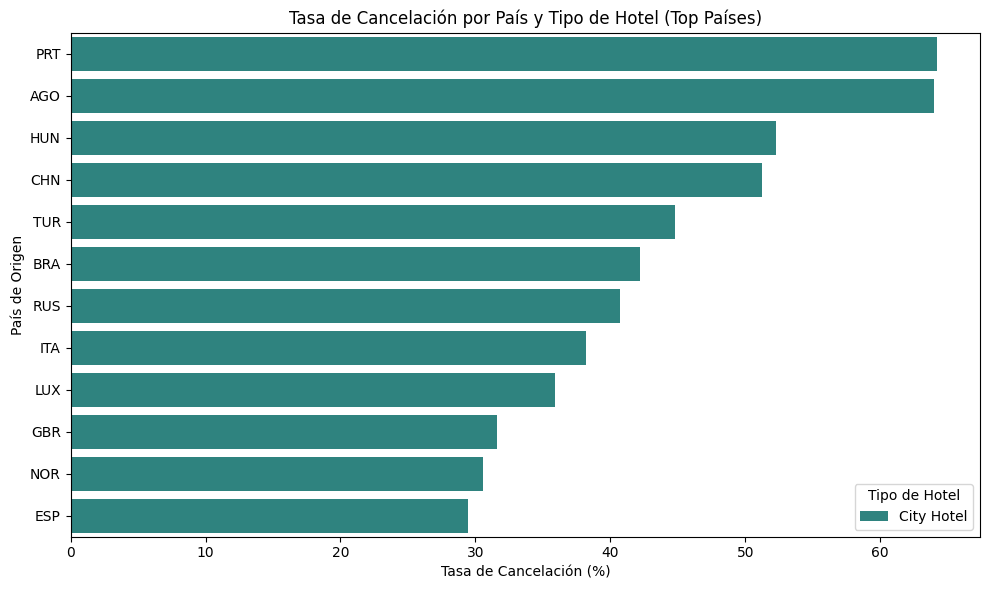

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tomamos un subconjunto top para que el gráfico sea legible (por ejemplo, los 10 con mayor tasa o más volumen)
plt.figure(figsize=(10, 6))
top_paises = df_pais_cancelacion.head(12)

sns.barplot(
    data=top_paises,
    x='tasa_cancelacion_porcentaje',
    y='country',
    hue='hotel',
    palette='viridis'
)

plt.title('Tasa de Cancelación por País y Tipo de Hotel (Top Países)')
plt.xlabel('Tasa de Cancelación (%)')
plt.ylabel('País de Origen')
plt.legend(title='Tipo de Hotel')
plt.tight_layout()
plt.show()

Portugal (PRT) concentra el mayor volumen analizado en los hoteles urbanos (25.93% del total general) con una alta tasa de cancelación del 64.19%, presentando además una amplia dispersión en el tiempo de anticipación (lead_time), con una mediana de 95 días y un tercer cuartil (Q75) de 221 días.

Otros mercados como Angola (AGO) y Hungría (HUN) también registran tasas de cancelación elevadas (64.00% y 52.27% respectivamente), pero con volúmenes de reservas significativamente menores y plazos de anticipación más cortos.

Observación exploratoria (Patrones detectados sin concluir causas):

Se identifica una marcada asimetría entre la media y la mediana del lead_time en países como Portugal y Hungría, lo que indica que los promedios están estirados hacia arriba por valores extremos de reservas hechas con mucha anticipación.

Estos patrones muestran una distribución heterogénea del comportamiento de cancelación y planificación según el país de origen, evidenciando diferencias que servirán como base para hipótesis futuras en las siguientes etapas del análisis.

<h2>"¿Qué canales de distribución comercial generan mayor volatilidad de cancelaciones ('clientes golondrina') al comparar los hoteles urbanos con los vacacionales?"</h2>

se calcula

**Volumen y Proporción:** La cantidad total de reservas (total_reservas) y qué porcentaje representa cada segmento dentro de su respectivo hotel (porcentaje_dentro_del_hotel).

**Nivel de Cancelación:** La cantidad de reservas caídas (reservas_canceladas) y su proporción exacta (tasa_cancelacion_porcentaje).

**Comportamiento del Pasajero:** El promedio de días de anticipación con el que reservan (lead_time_promedio) y la cantidad media de requerimientos especiales que realizan (promedio_solicitudes_especiales).

In [51]:
df_segmento_cancelacion = con.sql("""
    SELECT
        hotel,
        market_segment,
        COUNT(*) AS total_reservas,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(PARTITION BY hotel), 2) AS porcentaje_dentro_del_hotel,
        SUM(is_canceled) AS reservas_canceladas,
        ROUND(SUM(is_canceled) * 100.0 / COUNT(*), 2) AS tasa_cancelacion_porcentaje,
        ROUND(AVG(lead_time), 1) AS lead_time_promedio,
        ROUND(AVG(total_of_special_requests), 1) AS promedio_solicitudes_especiales
    FROM
        hotel_bookings
    GROUP BY
        hotel,
        market_segment
    ORDER BY
        hotel ASC,
        tasa_cancelacion_porcentaje DESC;
""").df()

print("Consulta ejecutada con éxito. Datos almacenados en df_segmento_cancelacion.")

Consulta ejecutada con éxito. Datos almacenados en df_segmento_cancelacion.


In [52]:
display(df_segmento_cancelacion)

,hotel,market_segment,total_reservas,porcentaje_dentro_del_hotel,reservas_canceladas,tasa_cancelacion_porcentaje,lead_time_promedio,promedio_solicitudes_especiales
0,City Hotel,Groups,2916,17.55,2028.0,69.55,195.6,0.1
1,City Hotel,Offline TA/TO,3495,21.04,1451.0,41.52,143.8,0.2
2,City Hotel,Online TA,8070,48.57,3068.0,38.02,82.5,0.9
3,City Hotel,Corporate,641,3.86,147.0,22.93,26.2,0.3
4,City Hotel,Aviation,46,0.28,10.0,21.74,4.4,0.1
5,City Hotel,Direct,1346,8.10,220.0,16.34,52.5,0.6
6,City Hotel,Complementary,100,0.60,7.0,7.00,7.7,1.1
7,Resort Hotel,Groups,1249,14.89,527.0,42.19,168.7,0.1
8,Resort Hotel,Online TA,3617,43.13,1301.0,35.97,84.0,1.0
9,Resort Hotel,Corporate,498,5.94,73.0,14.66,19.3,0.1


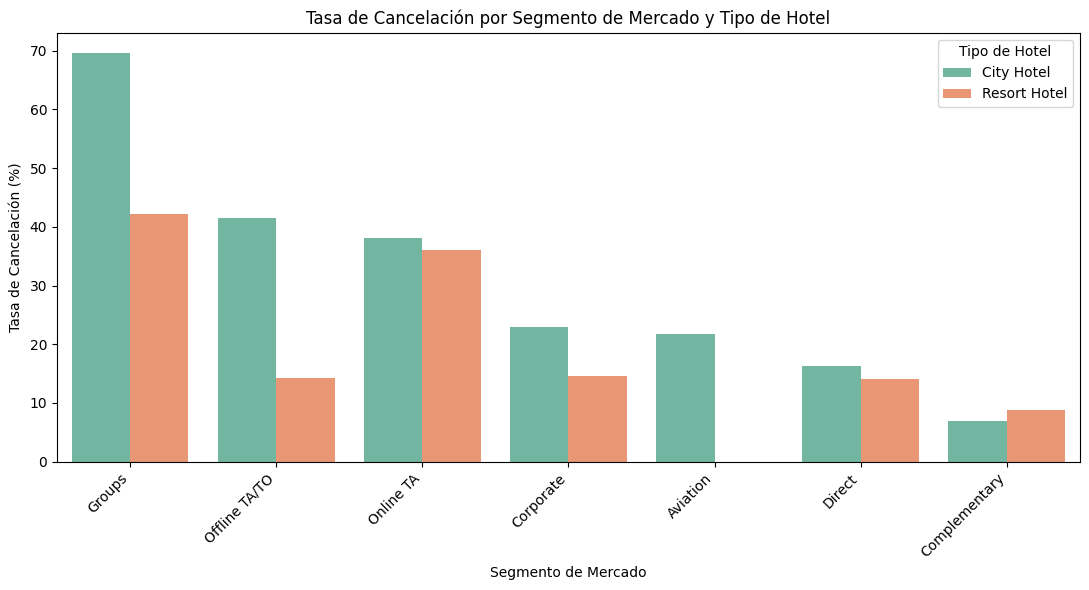

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))
sns.barplot(
    data=df_segmento_cancelacion,
    x='market_segment',
    y='tasa_cancelacion_porcentaje',
    hue='hotel',
    palette='Set2'
)

plt.title('Tasa de Cancelación por Segmento de Mercado y Tipo de Hotel')
plt.xlabel('Segmento de Mercado')
plt.ylabel('Tasa de Cancelación (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Tipo de Hotel')
plt.tight_layout()
plt.show()

**Descripción de los datos:**

Online TA representa el segmento con mayor volumen de reservas tanto en City Hotel (48.57%) como en Resort Hotel (43.13%), registrando tasas de cancelación moderadas cercanas al 38.02% y 35.97% respectivamente.

El segmento Groups en City Hotel concentra la tasa de cancelación más alta (69.55%), con un tiempo de anticipación promedio elevado (195.6 días) y el menor nivel de solicitudes especiales (0.1).

Los segmentos corporativos (Corporate) y directos (Direct) muestran menor volatilidad en las cancelaciones, con tasas que oscilan entre el 14% y el 22%, además de plazos de anticipación considerablemente más cortos.

**Observación exploratoria (Patrones detectados):**

Se observa una disparidad notable en el comportamiento de cancelación según el canal comercial: los canales masivos o de grupos presentan mayor inestabilidad que las reservas directas o corporativas.

Las métricas de solicitudes especiales se mantienen consistentemente bajas (entre 0.1 y 1.1) en todos los segmentos, marcando un patrón heterogéneo que evidencia diferencias en el perfil de los clientes según su canal de origen, sirviendo de base para futuras hipótesis.

<h2>¿El tipo de depósito (`deposit_type`) permite reconocer grupos con comportamientos de cancelación diferentes? relacionado al tipo de hotel</h2>

<p> segun metodo de pago se cancela o no, en un tipo de hotel u otro </p>

In [49]:
# Tabla de frecuencias de deposit_type segmentada por tipo de hotel y su tasa de cancelación
con.sql("""
SELECT
    hotel,
    deposit_type,
    SUM(CASE WHEN is_canceled = 0 THEN 1 ELSE 0 END) AS no_canceladas,
    SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) AS canceladas,
    COUNT(*) AS total_general,
    ROUND(SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS tasa_cancelacion_pct
FROM hotel_bookings
GROUP BY hotel, deposit_type
ORDER BY hotel, tasa_cancelacion_pct DESC;
""")


┌──────────────┬──────────────┬───────────────┬────────────┬───────────────┬──────────────────────┐
│    hotel     │ deposit_type │ no_canceladas │ canceladas │ total_general │ tasa_cancelacion_pct │
│   varchar    │   varchar    │    int128     │   int128   │     int64     │        double        │
├──────────────┼──────────────┼───────────────┼────────────┼───────────────┼──────────────────────┤
│ City Hotel   │ Refundable   │             0 │          1 │             1 │                100.0 │
│ City Hotel   │ Non Refund   │             5 │       2687 │          2692 │                99.81 │
│ City Hotel   │ No Deposit   │          9678 │       4243 │         13921 │                30.48 │
│ Resort Hotel │ Non Refund   │            10 │        381 │           391 │                97.44 │
│ Resort Hotel │ No Deposit   │          6017 │       1942 │          7959 │                 24.4 │
│ Resort Hotel │ Refundable   │            31 │          5 │            36 │                13.89 │


Estos patrones detectados no constituyen una conclusión cerrada, sino que funcionan como evidencia descriptiva inicial y señalan qué variables (como el tipo de depósito y la tarifa) ameritan un análisis más profundo en las etapas posteriores del trabajo.

In [45]:
df_deposit_cancelacion = con.sql("""
    SELECT
        hotel,
        deposit_type,
        COUNT(*) AS total_reservas,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(PARTITION BY hotel), 2) AS porcentaje_dentro_del_hotel,
        SUM(is_canceled) AS reservas_canceladas,
        ROUND(SUM(is_canceled) * 100.0 / COUNT(*), 2) AS tasa_cancelacion_porcentaje,
        ROUND(AVG(lead_time), 1) AS lead_time_promedio,
        ROUND(AVG(total_of_special_requests), 1) AS promedio_solicitudes_especiales
    FROM
        hotel_bookings
    GROUP BY
        hotel,
        deposit_type
    ORDER BY
        hotel ASC,
        tasa_cancelacion_porcentaje DESC;
""").df()

print("Consulta ejecutada con éxito. Datos almacenados en df_deposit_cancelacion.")

Consulta ejecutada con éxito. Datos almacenados en df_deposit_cancelacion.


In [ ]:
display(df_deposit_cancelacion)

In [ ]:
df_deposit_cancelacion

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.barplot(
    data=df_deposit_cancelacion,
    x='deposit_type',
    y='tasa_cancelacion_porcentaje',
    hue='hotel',
    palette='muted'
)

plt.title('Tasa de Cancelación por Tipo de Depósito y Tipo de Hotel')
plt.xlabel('Tipo de Depósito (Deposit Type)')
plt.ylabel('Tasa de Cancelación (%)')
plt.legend(title='Tipo de Hotel')
plt.tight_layout()
plt.show()